In [90]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [91]:
df = pd.read_csv(r"C:\Users\user\OneDrive\Desktop\ML_Learning\Project_1\data\Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [92]:
df.shape

(7043, 21)

In [93]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [94]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [95]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [96]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")


In [97]:
df["TotalCharges"].info()


<class 'pandas.Series'>
RangeIndex: 7043 entries, 0 to 7042
Series name: TotalCharges
Non-Null Count  Dtype  
--------------  -----  
7032 non-null   float64
dtypes: float64(1)
memory usage: 55.2 KB


In [98]:
df["TotalCharges"].isna().sum()

np.int64(11)

In [99]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [100]:
df["TotalCharges"].isna().sum()


np.int64(0)

In [101]:
df.duplicated().sum()



np.int64(0)

In [102]:
df["customerID"].duplicated().sum()

np.int64(0)

In [103]:
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [104]:
df[["tenure","MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


array([[<Axes: title={'center': 'tenure'}>,
        <Axes: title={'center': 'MonthlyCharges'}>],
       [<Axes: title={'center': 'TotalCharges'}>, <Axes: >]], dtype=object)

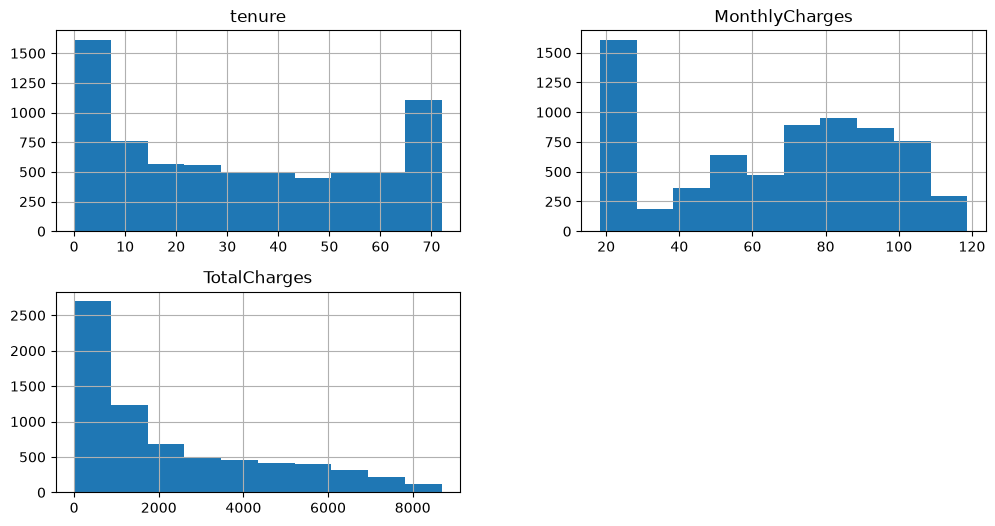

In [105]:
df[["tenure","MonthlyCharges", "TotalCharges"]].hist(figsize=(12,6))

In [106]:
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [107]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
)

Churn,No,Yes
Contract,,
Month-to-month,0.572903,0.427097
One year,0.887305,0.112695
Two year,0.971681,0.028319


In [108]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
)*100
#Fiber optic gerçekten churn'e sebep olan şey mi, 
# yoksa fiber kullanan müşterilerin başka özellikleri mi farklı?

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


In [109]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

<Axes: title={'center': 'MonthlyCharges'}, xlabel='Churn'>

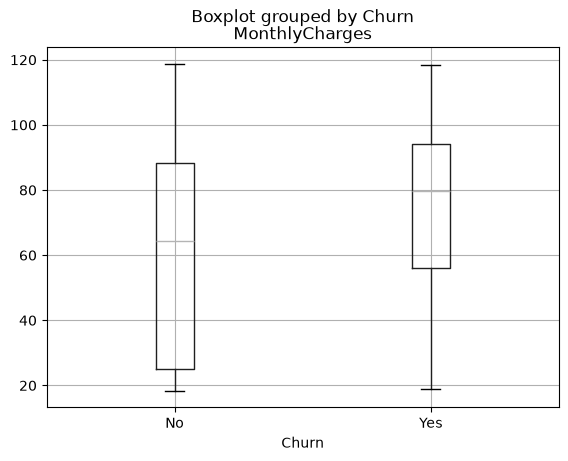

In [110]:
df.boxplot(column="MonthlyCharges", by="Churn")

<Axes: title={'center': 'tenure'}, xlabel='Churn'>

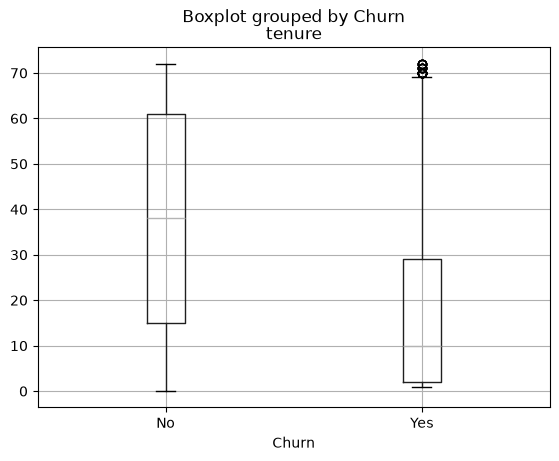

In [111]:
df.boxplot(column="tenure", by="Churn")

In [112]:
df.groupby("Churn")["tenure"].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [113]:
df["Churn_numeric"] = df["Churn"].map({"No": 0, "Yes": 1})

In [114]:
def churn_rate(column):
    return (
        df.groupby(column)["Churn_numeric"]
        .agg(["mean","count"])
    )
display(churn_rate("PaymentMethod"))
display(churn_rate("TechSupport"))
display(churn_rate("OnlineSecurity"))



,mean,count
PaymentMethod,,
Bank transfer (automatic),0.167098,1544
Credit card (automatic),0.152431,1522
Electronic check,0.452854,2365
Mailed check,0.191067,1612


,mean,count
TechSupport,,
No,0.416355,3473
No internet service,0.074050,1526
Yes,0.151663,2044


,mean,count
OnlineSecurity,,
No,0.417667,3498
No internet service,0.074050,1526
Yes,0.146112,2019


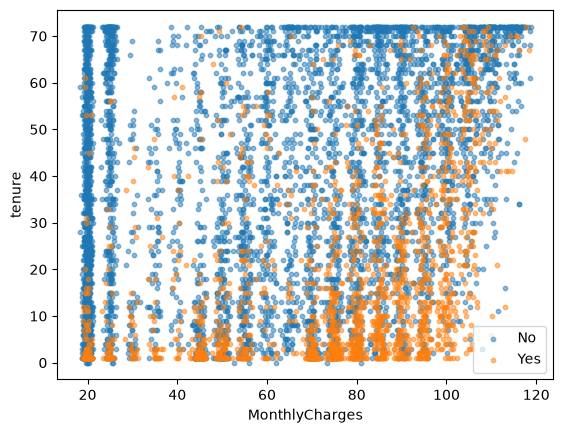

In [115]:

for churn in ["No", "Yes"]:
    group = df[df["Churn"] == churn]

    plt.scatter(
        group["MonthlyCharges"],
        group["tenure"],
        alpha=0.5,
        s=10,
        label=churn
       
    )

plt.xlabel("MonthlyCharges")
plt.ylabel("tenure")
plt.legend()
plt.show()

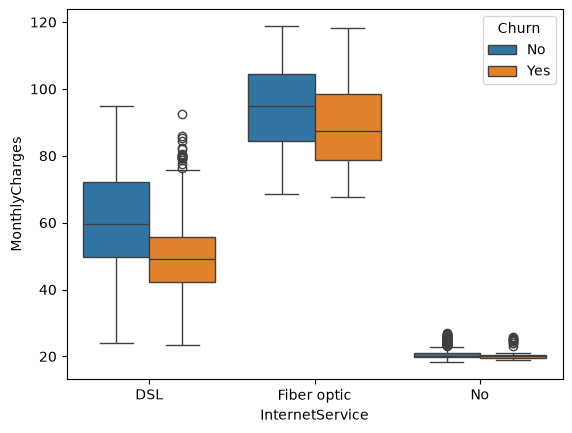

In [116]:
sns.boxplot(
    data=df,
    x="InternetService",
    y="MonthlyCharges",
    hue="Churn"
)

plt.show()



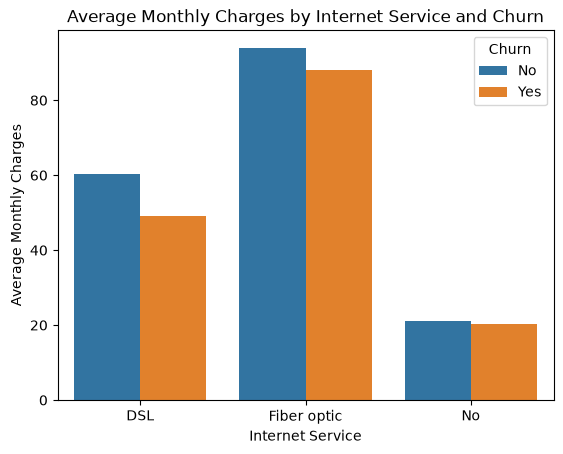

In [117]:



sns.barplot(
    data=df,
    x="InternetService",
    y="MonthlyCharges",
    hue="Churn",
    errorbar=None
)

plt.xlabel("Internet Service")
plt.ylabel("Average Monthly Charges")
plt.title("Average Monthly Charges by Internet Service and Churn")
plt.show()



## Çıkarımlarım 
1. Fiber optic kullananlarda churn daha yüksek.
2. Tenure düşük olanlarda churn daha yüksek.
3. Ama tenure tek başına yeterli açıklayıcı değil; başka değişkenlerle birlikte anlam kazanıyor.
4. MonthlyCharges yüksek olanlarda churn daha yüksek.
5. Fiber optic kullanıcılarının MonthlyCharges değerleri de belirgin şekilde daha yüksek.

In [131]:
#test ve train seti ayırdık sonrasında oranlar doğru dağılmış mı diye baktık 
# bazen dağılmıyor bu da bize sorun çıkarabilirdi
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Churn"]
)
print(df["InternetService"].value_counts(normalize=True))
print(train_set["InternetService"].value_counts(normalize=True))
print(test_set["InternetService"].value_counts(normalize=True))
print(df["tenure"].mean())
print(train_set["tenure"].mean())
print(test_set["tenure"].mean())
print(df["MonthlyCharges"].mean())
print(train_set["MonthlyCharges"].mean())
print(test_set["MonthlyCharges"].mean())

InternetService
Fiber optic    0.439585
DSL            0.343746
No             0.216669
Name: proportion, dtype: float64
InternetService
Fiber optic    0.440717
DSL            0.343805
No             0.215477
Name: proportion, dtype: float64
InternetService
Fiber optic    0.435060
DSL            0.343506
No             0.221434
Name: proportion, dtype: float64
32.37114865824223
32.48509052183174
31.91554293825408
64.76169246059918
64.92996095136671
64.0888573456352


In [132]:

display(train_set.head())
display(train_set.describe())
display(df.describe())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_numeric
3738,4950-BDEUX,Male,0,No,No,35,No,No phone service,DSL,No,...,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65,No,0
3151,7993-NQLJE,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,...,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55,No,0
4860,7321-ZNSLA,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,...,Yes,No,No,Two year,No,Mailed check,40.55,590.35,No,0
3867,4922-CVPDX,Female,0,Yes,No,26,Yes,No,DSL,No,...,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70,No,0
3810,2903-YYTBW,Male,0,Yes,Yes,1,Yes,No,DSL,No,...,No,No,No,Month-to-month,No,Electronic check,44.55,44.55,No,0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_numeric
count,5634.000000,5634.000000,5634.000000,5634.000000,5634.000000
mean,0.163294,32.485091,64.929961,2299.334682,0.265353
std,0.369667,24.568744,30.138105,2279.204278,0.441560
min,0.000000,0.000000,18.400000,0.000000,0.000000
25%,0.000000,9.000000,35.662500,402.975000,0.000000
50%,0.000000,29.000000,70.500000,1394.925000,0.000000
75%,0.000000,55.000000,90.000000,3835.825000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn_numeric
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,0.265370
std,0.368612,24.559481,30.090047,2266.794470,0.441561
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,0.000000
50%,0.000000,29.000000,70.350000,1394.550000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000


In [133]:
train_set = train_set.drop("customerID",axis=1)
test_set = test_set.drop("customerID",axis=1)

In [134]:
x_train = train_set.drop("Churn",axis=1)
y_train = train_set["Churn"]

x_test = test_set.drop("Churn" , axis=1)
y_test = test_set["Churn"]

In [135]:
#sayısal ve kategori olarak iki tane array oluşturduk işlem kolaylığı sağlaycaktır
#churn numeric data leakage yol açabileceği için çıkarttık
x_train_num = x_train.select_dtypes(include=["int64", "float64"]).drop("Churn_numeric",axis=1).copy()
x_train_cat = x_train.select_dtypes(include=["str", "category"]).copy()
#Senior citizen sadece 0 ve 1 den oluştuğu için onu kategorisele attık
x_train_cat["SeniorCitizen"] = x_train_num.pop("SeniorCitizen")
#Senir Citizen değerini 1hotencodera sokacağımız için no ve yes e çevirdik 
x_train_cat["SeniorCitizen"] = x_train_cat["SeniorCitizen"].map({
    0:"No",
    1: "Yes"
})


display(print(x_train_cat))
display(print(x_train_num))


#senior citizen 

      gender Partner Dependents PhoneService     MultipleLines  \
3738    Male      No         No           No  No phone service   
3151    Male     Yes        Yes          Yes                No   
4860    Male     Yes        Yes           No  No phone service   
3867  Female     Yes         No          Yes                No   
3810    Male     Yes        Yes          Yes                No   
...      ...     ...        ...          ...               ...   
6303  Female     Yes         No          Yes               Yes   
6227    Male      No         No          Yes                No   
4673  Female      No         No          Yes               Yes   
2710  Female     Yes         No          Yes                No   
5639    Male      No         No          Yes                No   

     InternetService       OnlineSecurity         OnlineBackup  \
3738             DSL                   No                   No   
3151     Fiber optic                  Yes                   No   
4860     

None

      tenure  MonthlyCharges  TotalCharges
3738      35           49.20       1701.65
3151      15           75.10       1151.55
4860      13           40.55        590.35
3867      26           73.50       1905.70
3810       1           44.55         44.55
...      ...             ...           ...
6303      71          109.25       7707.70
6227       2           46.05         80.35
4673      25          102.80       2660.20
2710      24           20.40        482.80
5639       6           20.65        109.30

[5634 rows x 3 columns]


None

In [136]:
#missing values yok şuan da ama yine de simpleimputer kullanalım 

from sklearn.impute import SimpleImputer

imputer= SimpleImputer(strategy="median")
imputer.fit(x_train_num)

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['tenure','MonthlyCharges','TotalCharges']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](3,)","[ 29. , 70.5 ,1394.92]"


In [137]:
#onehotencoder kullanarak categorileri encode edicez bu nedenle dataframeden array e çevirmemiz lazım
#ihtiyaç olur diyede dataframe olarak kopyasını oluşturalım 
x_train_num_df = x_train_num.copy()
x_train_num_imputed = imputer.transform(x_train_num)



In [138]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder(handle_unknown="ignore")

x_train_cat_1hot = cat_encoder.fit_transform(x_train_cat)
cat_encoder.categories_

[array(['Female', 'Male'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['No', 'No phone service', 'Yes'], dtype=object),
 array(['DSL', 'Fiber optic', 'No'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['No', 'No internet service', 'Yes'], dtype=object),
 array(['Month-to-month', 'One year', 'Two year'], dtype=object),
 array(['No', 'Yes'], dtype=object),
 array(['Bank transfer (automatic)', 'Credit card (automatic)',
        'Electronic check', 'Mailed check'], dtype=object),
 array(['No', 'Yes'], dtype=object)]

In [139]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_num_scaled = scaler.fit_transform(x_train_num_imputed)

x_train_num_scaled

array([[ 0.10237124, -0.52197565, -0.2622572 ],
       [-0.71174346,  0.33747781, -0.50363479],
       [-0.79315493, -0.80901319, -0.74988292],
       ...,
       [-0.30468611,  1.25666162,  0.15834357],
       [-0.34539184, -1.47766135, -0.79707463],
       [-1.07809507, -1.46936546, -0.96096216]], shape=(5634, 3))

In [140]:
#çok fazla negatif sayı var onları kontrol edicez
scaled_df = pd.DataFrame(
    x_train_num_scaled,
    columns=x_train_num.columns
)


scaled_df.describe()


,tenure,MonthlyCharges,TotalCharges
count,5.634000e+03,5.634000e+03,5.634000e+03
mean,-1.008935e-17,-2.402527e-16,2.522338e-17
std,1.000089e+00,1.000089e+00,1.000089e+00
min,-1.322329e+00,-1.544028e+00,-1.008922e+00
25%,-9.559779e-01,-9.711977e-01,-8.321009e-01
50%,-1.418632e-01,1.848336e-01,-3.968446e-01
75%,9.164859e-01,8.319124e-01,6.741944e-01
max,1.608483e+00,1.785939e+00,2.801869e+00
